### 04 cheklovsiz ketadigon

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

URL = "https://raw.githubusercontent.com/kb22/" \
      "Heart-Disease-Prediction/master/dataset.csv"

df = pd.read_csv(URL)


X = df.drop(columns=["target"])
y = df["target"]

# test_size = 0.3 qib korsak
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# checksiz ketadigon
unlimited = DecisionTreeClassifier(random_state=42)
unlimited.fit(X_train, y_train)

print(unlimited.score(X_train, y_train), unlimited.score(X_test, y_test)) # 1.0 0.7252747252747253

# test size oshirganimizga train qilishga malumot kam qoldi shunga model yaxshi bomadi, trainda overfiting va testda sezilarli darajada pasaydi accuracy

1.0 0.7252747252747253


### 05 prepruning

In [3]:
prepruning = DecisionTreeClassifier(max_depth=3, min_samples_leaf=5 ,random_state=42)
prepruning.fit(X_train, y_train)

print(prepruning.score(X_train, y_train), prepruning.score(X_test, y_test))# 0.8632075471698113 0.7472527472527473

# prepruning yani limits qoyganimizdan keyin train accuracy camaydi lekin testda sal yaxshiroq natija korsatdi, va stability bor boldi

0.8632075471698113 0.7472527472527473


# task 2 grafik chizish

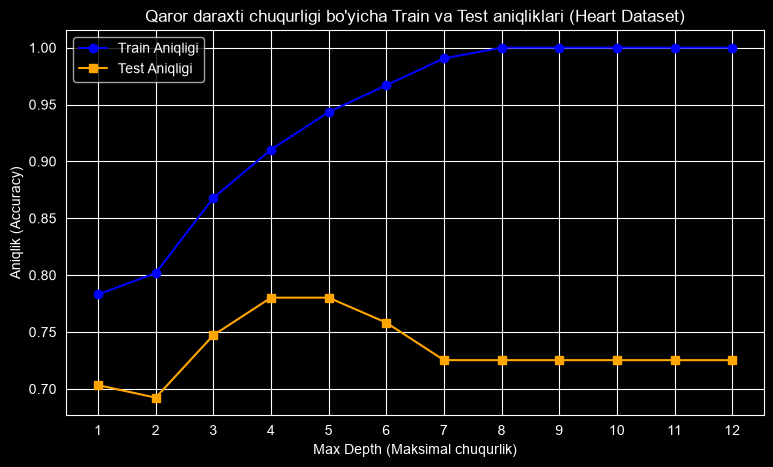

In [6]:
# 1. max_depth=1 dan 12 gacha hisoblash
depths = range(1, 13)
train_acc = []
test_acc = []

for depth in depths:
  clf = DecisionTreeClassifier(max_depth=depth, random_state=42)
  clf.fit(X_train, y_train)
  train_acc.append(clf.score(X_train, y_train))
  test_acc.append(clf.score(X_test, y_test))

# 2. Grafikni chizish
plt.figure(figsize=(9, 5))
plt.plot(depths, train_acc, label="Train accuracy", marker="o", color="blue")
plt.plot(depths, test_acc, label="Test accuracy", marker="s", color="orange")
plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.title(
    "Qaror daraxti chuqurligi bo'yicha Train va Test accuracy"
)
plt.xticks(depths)
plt.legend()
plt.grid(True)
plt.show()

# Building tree model with titanic dataset

In [12]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import export_text

In [10]:
# load dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

# select useful features // encode gender
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

X = df[["Pclass", "Sex", "Age", "Fare"]]
y = df["Survived"]

# train split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# missing valuesni imputer blan fill and first unlimited decision tree
unlimited_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("tree", DecisionTreeClassifier(random_state=42))
])

unlimited_pipe.fit(X_train, y_train)

print(unlimited_pipe.score(X_train, y_train), unlimited_pipe.score(X_test, y_test)) #0.9817415730337079                 0.7988826815642458

# now preprunning blan
prepruning_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("tree", DecisionTreeClassifier(max_depth=4, min_samples_leaf=10 ,random_state=42))
])
prepruning_pipe.fit(X_train, y_train)

print(prepruning_pipe.score(X_train, y_train), prepruning_pipe.score(X_test, y_test))#0.8286516853932584             0.7653631284916201

0.9817415730337079 0.7988826815642458
0.8286516853932584 0.7653631284916201


# task 4

In [18]:
# Get the trained decision tree model from the pipeline
tree_model = prepruning_pipe.named_steps["tree"]
feature_names = ["Pclass", "Sex", "Age", "Fare"]

# Print the text representation of the tree
print(export_text(tree_model, feature_names=feature_names))


# first checks if woman or not
# secondly age, children
# thirdly class, if first class weight more
# finally fare, like how much you spend on tickets

|--- Sex <= 0.50
|   |--- Age <= 3.50
|   |   |--- class: 1
|   |--- Age >  3.50
|   |   |--- Pclass <= 1.50
|   |   |   |--- Fare <= 26.14
|   |   |   |   |--- class: 0
|   |   |   |--- Fare >  26.14
|   |   |   |   |--- class: 0
|   |   |--- Pclass >  1.50
|   |   |   |--- Fare <= 51.70
|   |   |   |   |--- class: 0
|   |   |   |--- Fare >  51.70
|   |   |   |   |--- class: 0
|--- Sex >  0.50
|   |--- Pclass <= 2.50
|   |   |--- Fare <= 28.86
|   |   |   |--- Age <= 37.00
|   |   |   |   |--- class: 1
|   |   |   |--- Age >  37.00
|   |   |   |   |--- class: 1
|   |   |--- Fare >  28.86
|   |   |   |--- Fare <= 149.04
|   |   |   |   |--- class: 1
|   |   |   |--- Fare >  149.04
|   |   |   |   |--- class: 1
|   |--- Pclass >  2.50
|   |   |--- Fare <= 23.35
|   |   |   |--- Fare <= 7.89
|   |   |   |   |--- class: 1
|   |   |   |--- Fare >  7.89
|   |   |   |   |--- class: 0
|   |   |--- Fare >  23.35
|   |   |   |--- class: 0

